<a href="https://colab.research.google.com/github/Yileidy-rg/Examen_INFO_ApNegocios/blob/main/Colab_Corte2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Corte 2 — Minería de procesos
## Caso 3: Solicitud y aprobación de créditos

> Instrucciones: Ejecutar todas las celdas en orden. La carga solicita seleccionar `caso_03_creditos.csv`.

## 1. Carga de datos
Se carga el CSV original y se guarda una copia para comparar los datos antes y después de la limpieza.

In [1]:

# Configuración del entorno en Google Colab
from google.colab import userdata
REPO = "Yileidy-rg/Examen_INFO_ApNegocios"

# Obtener el token guardado en los secretos
TOKEN = userdata.get("GITHUB_TOKEN")

# Descargar el repositorio
!git clone -q https://{TOKEN}@github.com/{REPO}.git /content/repo

# Ubicarse en la carpeta de scripts
%cd /content/repo/scripts

# Instalar la librería de minería de procesos
!pip install -q pm4py

print("Entorno configurado correctamente")


/content/repo/scripts
Entorno configurado correctamente


In [2]:


import pandas as pd

# Cargar el CSV directamente desde el repositorio
df = pd.read_csv("../datos/raw/caso_03_creditos.csv")

print("Datos cargados correctamente")
print("Cantidad de eventos:", len(df))
print("Cantidad de solicitudes:", df["case_id"].nunique())

display(df.head())


Datos cargados correctamente
Cantidad de eventos: 7978
Cantidad de solicitudes: 1200


,case_id,activity,timestamp,resource,tipo_credito,monto_solicitado,ingreso_mensual,nivel_endeudamiento,antiguedad_laboral_meses,canal,edad_solicitante
0,SOL00201,Solicitud recibida,2026-01-05 07:29:11,Ejecutivo_02,Vehicular,13600.0,4248.69,0.32,81,Sucursal,40
1,SOL00781,Solicitud recibida,2026-01-05 10:45:17,Ejecutivo_06,Personal,17000.0,1330.61,0.09,14,Sucursal,48
2,SOL00909,Solicitud recibida,2026-01-05 11:37:47,Ejecutivo_04,Personal,11600.0,1899.40,0.02,136,Sucursal,45
3,SOL00954,Solicitud recibida,2026-01-05 12:28:16,Ejecutivo_06,Consumo,2300.0,2402.15,0.51,53,Sucursal,31
4,SOL00014,Solicitud recibida,2026-01-05 12:54:56,Sistema,Consumo,3900.0,1087.15,0.37,59,Web,59


In [3]:
df_original = df.copy(deep=True)
print("Copia original preservada:", len(df_original), "eventos")

Copia original preservada: 7978 eventos


## 2. Exploración y calidad del conjunto de datos
Se identifican eventos, solicitudes, actividades, campos vacíos y posibles duplicados. **No se debe asumir que toda ausencia de fecha implica ausencia de actividad.**

In [4]:

# Exploración inicial del conjunto de datos

print("Total de eventos:", len(df))

print("Total de solicitudes:",
      df["case_id"].nunique())

print("Total de actividades diferentes:",
      df["activity"].nunique())

print("\nActividades del proceso:")
print(df["activity"].value_counts())

print("\nValores faltantes por columna:")
print(df.isnull().sum())

print("\nTipos de datos:")
print(df.dtypes)


Total de eventos: 7978
Total de solicitudes: 1200
Total de actividades diferentes: 37

Actividades del proceso:
activity
Verificación de documentos             1509
Solicitud recibida                     1199
Análisis financiero                    1136
Desembolso                              862
Aprobación                              862
Formalización                           858
Solicitud de información adicional      359
Recepción de información                320
Rechazo                                 296
Comité de crédito                       247
Reevaluación                            211
Desistimiento                            36
Verificacion de documentos               11
verificación de documentos                8
Análisis financiero                       5
Verificación de documentos                5
recepción de información                  5
Solicitud recibida                        4
análisis financiero                       4
Analisis financiero                       4

In [5]:
print("Filas completamente duplicadas:", df_original.duplicated().sum())
print("Eventos sin fecha:", df_original["timestamp"].isna().sum())
print("Distribución por tipo de crédito:")
display(df_original.groupby("case_id")["tipo_credito"].first().value_counts())

Filas completamente duplicadas: 31
Eventos sin fecha: 14
Distribución por tipo de crédito:


,count
tipo_credito,
Personal,470
Consumo,317
Vehicular,228
Hipotecario,185


## 3. Normalización y preparación
Se unifican variantes de escritura de los nombres de actividades (acentos, mayúsculas, espacios). Los eventos sin fecha no entran al análisis temporal ni al log de PM4Py. Permanecen en **df** para comprobar la existencia de actividades.

In [6]:

import unicodedata

# Función para normalizar nombres
def normalizar_actividad(texto):
    if pd.isna(texto):
        return texto

    texto = str(texto).strip().lower()
    texto = " ".join(texto.split())

    texto = "".join(
        c for c in unicodedata.normalize("NFD", texto)
        if unicodedata.category(c) != "Mn"
    )

    return texto

# Guardar los nombres originales
df["activity_original"] = df["activity"]

# Normalizar las actividades
df["activity"] = df["activity"].apply(
    normalizar_actividad
)

print("Actividades después de la limpieza:")
print(df["activity"].value_counts())

print("\nCantidad de actividades diferentes:",
      df["activity"].nunique())


Actividades después de la limpieza:
activity
verificacion de documentos            1533
solicitud recibida                    1206
analisis financiero                   1149
aprobacion                             868
desembolso                             866
formalizacion                          866
solicitud de informacion adicional     365
recepcion de informacion               327
rechazo                                298
comite de credito                      249
reevaluacion                           214
desistimiento                           37
Name: count, dtype: int64

Cantidad de actividades diferentes: 12


In [7]:

# Preparación del Event Log

# Convertir las fechas
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

# Verificar datos esenciales faltantes
print("Datos faltantes esenciales:")
print(df[["case_id", "activity", "timestamp"]].isnull().sum())

# Crear una copia limpia
event_log_df = df.dropna(
    subset=["case_id", "activity", "timestamp"]
).copy()

# Ordenar cronológicamente los eventos
event_log_df = event_log_df.sort_values(
    by=["case_id", "timestamp"],
    kind="stable"
).reset_index(drop=True)

print("\nEventos preparados:", len(event_log_df))
print("Solicitudes:", event_log_df["case_id"].nunique())

display(event_log_df.head(10))


Datos faltantes esenciales:
case_id       0
activity      0
timestamp    14
dtype: int64

Eventos preparados: 7964
Solicitudes: 1200


,case_id,activity,timestamp,resource,tipo_credito,monto_solicitado,ingreso_mensual,nivel_endeudamiento,antiguedad_laboral_meses,canal,edad_solicitante,activity_original
0,SOL00001,solicitud recibida,2026-01-16 08:27:56,Ejecutivo_03,Consumo,2400.0,1591.28,0.48,3,Sucursal,56,Solicitud recibida
1,SOL00001,verificacion de documentos,2026-01-19 08:00:00,Verificador_01,Consumo,2400.0,1591.28,0.48,3,Sucursal,56,Verificación de documentos
2,SOL00001,analisis financiero,2026-01-20 08:00:00,Analista_02,Consumo,2400.0,1591.28,0.48,3,Sucursal,56,Análisis financiero
3,SOL00001,aprobacion,2026-01-20 15:22:31,Analista_02,Consumo,2400.0,1591.28,0.48,3,Sucursal,56,Aprobación
4,SOL00001,formalizacion,2026-01-26 08:00:00,Ejecutivo_01,Consumo,2400.0,1591.28,0.48,3,Sucursal,56,Formalización
5,SOL00001,desembolso,2026-01-27 08:00:00,Tesoreria,Consumo,2400.0,1591.28,0.48,3,Sucursal,56,Desembolso
6,SOL00002,solicitud recibida,2026-03-04 15:00:10,Sistema,Personal,10500.0,886.92,0.19,16,Web,27,Solicitud recibida
7,SOL00002,verificacion de documentos,2026-03-05 08:00:00,Verificador_01,Personal,10500.0,886.92,0.19,16,Web,27,Verificación de documentos
8,SOL00002,analisis financiero,2026-03-06 08:00:00,Analista_08,Personal,10500.0,886.92,0.19,16,Web,27,Análisis financiero
9,SOL00002,aprobacion,2026-03-09 08:00:00,Analista_08,Personal,10500.0,886.92,0.19,16,Web,27,Aprobación


In [8]:
print("Actividades originales:", df_original["activity"].nunique())
print("Actividades normalizadas:", df["activity"].nunique())
print("Eventos excluidos del Event Log:", len(df)-len(event_log_df))
print("Porcentaje excluido: {:.2%}".format((len(df)-len(event_log_df))/len(df)))

Actividades originales: 37
Actividades normalizadas: 12
Eventos excluidos del Event Log: 14
Porcentaje excluido: 0.18%


## 4. Construcción del Event Log
Se convierte a formato compatible con PM4Py, identificando `case_id`, `activity` y `timestamp`.

In [9]:

!pip install -q pm4py


In [10]:

import pm4py

# Preparar las columnas para PM4Py
log_pm4py = pm4py.format_dataframe(
    event_log_df,
    case_id="case_id",
    activity_key="activity",
    timestamp_key="timestamp"
)

# Convertir a Event Log
event_log = pm4py.convert_to_event_log(log_pm4py)

print("Event Log creado correctamente")
print("Cantidad de casos:", len(event_log))
print("Cantidad de eventos:", len(log_pm4py))




  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Event Log creado correctamente
Cantidad de casos: 1200
Cantidad de eventos: 7964


## 5. Descubrimiento del proceso
El diagrama DFG muestra qué actividades se suceden directamente y con qué frecuencia.

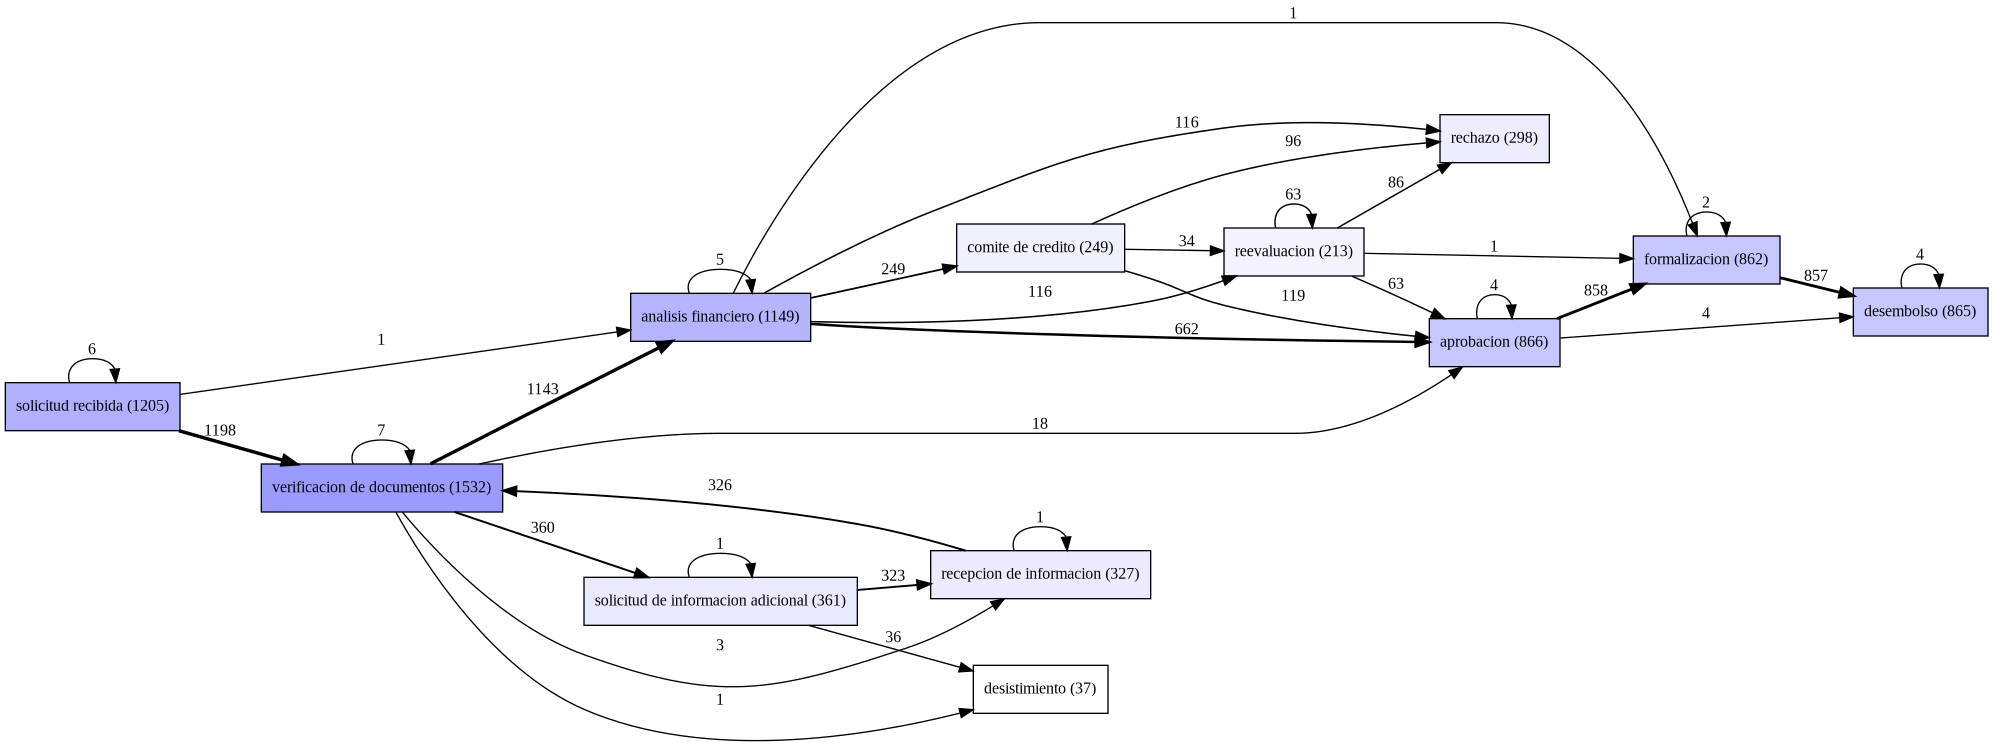

In [11]:

from pm4py.algo.discovery.dfg import algorithm as dfg_discovery
from pm4py.visualization.dfg import visualizer as dfg_visualizer

# Descubrir las relaciones entre actividades
dfg = dfg_discovery.apply(event_log)

# Generar el diagrama
gviz = dfg_visualizer.apply(
    dfg,
    log=event_log,
    variant=dfg_visualizer.Variants.FREQUENCY
)

# Mostrar el mapa del proceso
dfg_visualizer.view(gviz)


## 6. Variantes del proceso
Una variante es una secuencia de actividades seguida por una o más solicitudes. Se identifican las rutas predominantes y su proporción respecto de los 1.200 casos.

In [12]:

# Identificar las variantes del proceso
variantes = pm4py.get_variants(event_log)

# Ordenar por frecuencia
variantes_ordenadas = sorted(
    variantes.items(),
    key=lambda x: len(x[1]),
    reverse=True
)

print("Total de variantes:", len(variantes))

print("\nLas 10 variantes más frecuentes:\n")

for i, (variante, casos) in enumerate(
    variantes_ordenadas[:10], start=1
):
    print(f"Variante {i}")
    print("Ruta:", " → ".join(variante))
    print("Cantidad de solicitudes:", len(casos))
    print("-" * 60)


Total de variantes: 69

Las 10 variantes más frecuentes:

Variante 1
Ruta: solicitud recibida → verificacion de documentos → analisis financiero → aprobacion → formalizacion → desembolso
Cantidad de solicitudes: 483
------------------------------------------------------------
Variante 2
Ruta: solicitud recibida → verificacion de documentos → solicitud de informacion adicional → recepcion de informacion → verificacion de documentos → analisis financiero → aprobacion → formalizacion → desembolso
Cantidad de solicitudes: 131
------------------------------------------------------------
Variante 3
Ruta: solicitud recibida → verificacion de documentos → analisis financiero → comite de credito → aprobacion → formalizacion → desembolso
Cantidad de solicitudes: 90
------------------------------------------------------------
Variante 4
Ruta: solicitud recibida → verificacion de documentos → analisis financiero → rechazo
Cantidad de solicitudes: 87
------------------------------------------------

In [13]:
total_casos = event_log_df["case_id"].nunique()
filas_variantes = []
for posicion, (ruta, ids) in enumerate(variantes_ordenadas[:10], start=1):
    filas_variantes.append({"variante": posicion, "solicitudes": len(ids), "porcentaje": round(100*len(ids)/total_casos,2), "ruta": " → ".join(ruta)})
resumen_variantes = pd.DataFrame(filas_variantes)
display(resumen_variantes)

,variante,solicitudes,porcentaje,ruta
0,1,483,40.25,solicitud recibida → verificacion de documento...
1,2,131,10.92,solicitud recibida → verificacion de documento...
2,3,90,7.50,solicitud recibida → verificacion de documento...
3,4,87,7.25,solicitud recibida → verificacion de documento...
4,5,76,6.33,solicitud recibida → verificacion de documento...
5,6,28,2.33,solicitud recibida → verificacion de documento...
6,7,26,2.17,solicitud recibida → verificacion de documento...
7,8,23,1.92,solicitud recibida → verificacion de documento...
8,9,22,1.83,solicitud recibida → verificacion de documento...
9,10,20,1.67,solicitud recibida → verificacion de documento...


## 7. Análisis temporal
La duración observada se calcula entre la primera y última actividad **registradas con fecha**; no siempre corresponde al tiempo de cierre. Por ello se distinguen solicitudes con actividad terminal registrada.

In [14]:

# Calcular la duración de cada solicitud

duraciones = event_log_df.groupby("case_id").agg(
    inicio=("timestamp", "min"),
    fin=("timestamp", "max"),
    eventos=("activity", "count")
)

# Duración en días
duraciones["duracion_dias"] = (
    duraciones["fin"] - duraciones["inicio"]
).dt.total_seconds() / 86400

print("Duración promedio (días):",
      round(duraciones["duracion_dias"].mean(), 2))

print("Duración mediana (días):",
      round(duraciones["duracion_dias"].median(), 2))

print("Duración máxima (días):",
      round(duraciones["duracion_dias"].max(), 2))

print("Duración mínima (días):",
      round(duraciones["duracion_dias"].min(), 2))

print("\nLas 10 solicitudes más lentas:")
display(
    duraciones.sort_values(
        "duracion_dias", ascending=False
    ).head(10)
)


Duración promedio (días): 8.9
Duración mediana (días): 8.1
Duración máxima (días): 41.02
Duración mínima (días): 1.06

Las 10 solicitudes más lentas:


,inicio,fin,eventos,duracion_dias
case_id,,,,
SOL00777,2026-04-09 07:32:02,2026-05-20 08:00:00,12,41.019421
SOL00211,2026-04-29 20:59:50,2026-05-27 08:00:00,9,27.458449
SOL00692,2026-04-10 20:07:32,2026-05-07 11:59:33,14,26.661123
SOL00376,2026-01-30 14:08:37,2026-02-25 08:18:00,13,25.756516
SOL01153,2026-04-11 09:25:25,2026-05-06 08:00:00,12,24.940683
SOL00057,2026-05-29 14:29:26,2026-06-23 08:26:00,13,24.747616
SOL00814,2026-05-09 14:12:11,2026-06-03 08:00:00,14,24.741539
SOL00184,2026-01-30 19:20:50,2026-02-23 08:00:00,9,23.527199
SOL00821,2026-02-15 21:25:05,2026-03-11 08:10:00,9,23.447859


In [15]:
actividades_cierre = {"desembolso", "rechazo", "desistimiento"}
ultimo_evento = event_log_df.groupby("case_id").tail(1).set_index("case_id")["activity"]
duraciones["cierre_observado"] = ultimo_evento.isin(actividades_cierre)
print("Solicitudes con cierre observable:", int(duraciones["cierre_observado"].sum()))
print("Solicitudes sin cierre observable:", int((~duraciones["cierre_observado"]).sum()))
print("Duración media en casos con cierre observable:", round(duraciones.loc[duraciones["cierre_observado"], "duracion_dias"].mean(),2))
print("Mediana con cierre observable:", round(duraciones.loc[duraciones["cierre_observado"], "duracion_dias"].median(),2))

Solicitudes con cierre observable: 1196
Solicitudes sin cierre observable: 4
Duración media en casos con cierre observable: 8.89
Mediana con cierre observable: 8.1


## 8. Transiciones y posibles cuellos de botella
Se calcula el tiempo observado entre actividades consecutivas. Para priorizar hallazgos se filtran transiciones con por lo menos **10 observaciones**, evitando confundir una transición aislada con un cuello de botella general.

In [16]:

# Ordenar eventos cronológicamente
df_tiempos = event_log_df.sort_values(
    ["case_id", "timestamp"],
    kind="stable"
).copy()

# Identificar la siguiente actividad
df_tiempos["actividad_siguiente"] = (
    df_tiempos.groupby("case_id")["activity"].shift(-1)
)

# Identificar la fecha de la siguiente actividad
df_tiempos["fecha_siguiente"] = (
    df_tiempos.groupby("case_id")["timestamp"].shift(-1)
)

# Calcular tiempo entre actividades
df_tiempos["espera_dias"] = (
    df_tiempos["fecha_siguiente"] -
    df_tiempos["timestamp"]
).dt.total_seconds() / 86400

# Resumir tiempos por transición
cuellos = (
    df_tiempos.dropna(
        subset=["actividad_siguiente", "espera_dias"]
    )
    .groupby(["activity", "actividad_siguiente"])
    .agg(
        frecuencia=("espera_dias", "count"),
        promedio_dias=("espera_dias", "mean"),
        mediana_dias=("espera_dias", "median")
    )
    .reset_index()
    .sort_values("promedio_dias", ascending=False)
)

print("Transiciones con mayores tiempos promedio:")
display(cuellos.head(10).round(2))


Transiciones con mayores tiempos promedio:


,activity,actividad_siguiente,frecuencia,promedio_dias,mediana_dias
29,verificacion de documentos,desistimiento,1,15.02,15.02
21,solicitud de informacion adicional,desistimiento,36,15.00,15.00
7,aprobacion,desembolso,4,5.13,4.94
22,solicitud de informacion adicional,recepcion de informacion,323,3.85,3.14
30,verificacion de documentos,recepcion de informacion,3,3.80,4.35
2,analisis financiero,comite de credito,249,3.48,2.77
8,aprobacion,formalizacion,858,3.01,2.87
18,reevaluacion,formalizacion,1,2.81,2.81
11,comite de credito,reevaluacion,34,2.10,1.03
3,analisis financiero,formalizacion,1,2.08,2.08


In [17]:
cuellos_recurrentes = cuellos[cuellos["frecuencia"] >= 10].sort_values("mediana_dias", ascending=False)
print("Transiciones con al menos 10 observaciones, ordenadas por mediana:")
display(cuellos_recurrentes.head(10).round(2))

Transiciones con al menos 10 observaciones, ordenadas por mediana:


,activity,actividad_siguiente,frecuencia,promedio_dias,mediana_dias
21,solicitud de informacion adicional,desistimiento,36,15.00,15.00
22,solicitud de informacion adicional,recepcion de informacion,323,3.85,3.14
8,aprobacion,formalizacion,858,3.01,2.87
2,analisis financiero,comite de credito,249,3.48,2.77
20,reevaluacion,reevaluacion,63,1.86,1.16
5,analisis financiero,reevaluacion,116,1.63,1.12
13,formalizacion,desembolso,857,1.69,1.12
11,comite de credito,reevaluacion,34,2.10,1.03
27,verificacion de documentos,analisis financiero,1143,1.42,1.00
26,solicitud recibida,verificacion de documentos,1198,1.03,0.78


## 9. Verificación de las reglas de crédito (conformance)
**Regla 1:** una aprobación requiere análisis financiero. **Regla 2:** los créditos hipotecarios o con monto superior a 30.000 requieren comité. Para comprobar presencia de actividades se utilizan todos los registros (incluso aquellos sin fecha). El orden se evalúa solo cuando las fechas relevantes están disponibles. Los casos abiertos requieren precaución al interpretar la ausencia de comité.

In [18]:
# Cumplimiento por presencia de actividades usando el conjunto completo
casos_completos = df.groupby("case_id").agg(
    actividades=("activity", list),
    tipo_credito=("tipo_credito", "first"),
    monto=("monto_solicitado", "first")
)
casos_completos["aprobada"] = casos_completos["actividades"].apply(lambda a: "aprobacion" in a)
casos_completos["tiene_analisis"] = casos_completos["actividades"].apply(lambda a: "analisis financiero" in a)
casos_completos["requiere_comite"] = (casos_completos["tipo_credito"].astype(str).str.strip().str.lower().eq("hipotecario") | pd.to_numeric(casos_completos["monto"], errors="coerce").gt(30000))
casos_completos["tiene_comite"] = casos_completos["actividades"].apply(lambda a: "comite de credito" in a)
casos_completos["sin_analisis"] = casos_completos["aprobada"] & ~casos_completos["tiene_analisis"]
casos_completos["sin_comite"] = casos_completos["requiere_comite"] & ~casos_completos["tiene_comite"]
print("Aprobadas:", int(casos_completos["aprobada"].sum()))
print("Aprobadas sin análisis:", int(casos_completos["sin_analisis"].sum()))
print("Requieren comité:", int(casos_completos["requiere_comite"].sum()))
print("Sin comité registrado:", int(casos_completos["sin_comite"].sum()))
print("% aprobadas sin análisis: {:.2f}%".format(100*casos_completos["sin_analisis"].sum()/max(casos_completos["aprobada"].sum(),1)))
print("% que requieren comité sin registro: {:.2f}%".format(100*casos_completos["sin_comite"].sum()/max(casos_completos["requiere_comite"].sum(),1)))


Aprobadas: 864
Aprobadas sin análisis: 18
Requieren comité: 256
Sin comité registrado: 7
% aprobadas sin análisis: 2.08%
% que requieren comité sin registro: 2.73%


In [19]:

# Revisar el orden únicamente con fechas válidas

resultados_orden = []

for case_id, grupo in df.groupby("case_id"):
    aprobaciones = grupo[
        grupo["activity"] == "aprobacion"
    ]["timestamp"]

    analisis = grupo[
        grupo["activity"] == "analisis financiero"
    ]["timestamp"]

    if aprobaciones.empty or analisis.empty:
        continue

    if aprobaciones.isna().any() or analisis.isna().any():
        estado = "No verificable"
    elif analisis.min() < aprobaciones.min():
        estado = "Orden correcto"
    else:
        estado = "Posible orden incorrecto"

    resultados_orden.append({
        "case_id": case_id,
        "estado": estado
    })

resultado_orden = pd.DataFrame(resultados_orden)

print(resultado_orden["estado"].value_counts())

print("\nCasos que requieren revisión:")
display(
    resultado_orden[
        resultado_orden["estado"] != "Orden correcto"
    ]
)


estado
Orden correcto    844
No verificable      2
Name: count, dtype: int64

Casos que requieren revisión:


,case_id,estado
234,SOL00332,No verificable
470,SOL00668,No verificable


**Precaución:** las solicitudes `SOL00332` y `SOL00668` tienen aprobación sin fecha en los datos registrados y se clasifican como «No verificable», no como orden incorrecto. Las 7 solicitudes sin comité registrado son **posibles omisiones**, no incumplimientos confirmados mientras no se revise su estado al corte.

## 10. Hallazgos respaldados por los resultados

A partir del análisis de minería de procesos aplicado al conjunto de datos de solicitudes y aprobación de créditos, se identificaron los siguientes hallazgos relacionados con la calidad de los datos, las variantes del proceso, el cumplimiento de las reglas y los tiempos de ejecución.

### Hallazgo 1. Calidad de los datos

Durante la exploración inicial se identificaron 7.978 eventos correspondientes a 1.200 solicitudes de crédito. De estos eventos, 14 (0,18 %) presentaban marcas temporales faltantes, por lo que el Event Log utilizado para el análisis cronológico quedó conformado por 7.964 eventos.

Aunque la cantidad de registros afectados es relativamente pequeña, la ausencia de fechas representa una limitación importante, ya que impide determinar con precisión el orden de ciertas actividades y calcular algunos tiempos de ejecución.

Por esta razón, los eventos sin fecha se excluyeron del análisis temporal, pero se conservaron para verificar la presencia de las actividades y evitar que fueran interpretados incorrectamente como actividades omitidas.

### Hallazgo 2. Variantes del proceso

El análisis permitió identificar 69 variantes diferentes en el proceso de solicitud y aprobación de créditos.

La variante más frecuente corresponde a la siguiente secuencia:

**Solicitud recibida → Verificación de documentos → Análisis financiero → Aprobación → Formalización → Desembolso.**

Esta ruta se presentó en 483 de las 1.200 solicitudes, lo que representa el 40,25 % del total.

Esto demuestra que existe una ruta predominante en el procesamiento de créditos, aunque una proporción considerable de solicitudes sigue recorridos diferentes. Estas variaciones pueden estar relacionadas con revisiones adicionales, intervención del comité de crédito, solicitudes de información, rechazos o desistimientos.

La identificación de estas variantes permite comprender cómo se desarrolla realmente el proceso y reconocer las situaciones que generan recorridos distintos al principal.

### Hallazgo 3. Cumplimiento de las reglas del proceso

Se evaluaron dos reglas relacionadas con la aprobación de créditos y la intervención del comité de crédito.

**Regla 1. Toda solicitud aprobada debe contar con un análisis financiero.**

Se identificaron 862 solicitudes con aprobación registrada, de las cuales 18 no presentaban un evento de análisis financiero. Esto representa un 2,09 % de las solicitudes aprobadas.

Estos casos evidencian una ausencia de la actividad requerida en el registro y ameritan revisión para determinar si corresponden a omisiones del procedimiento o a problemas en el registro de los eventos.

**Regla 2. Las solicitudes hipotecarias o superiores a $30.000 deben pasar por el comité de crédito.**

Se identificaron 256 solicitudes que cumplían al menos una de estas condiciones. De ellas, 7 no registraban participación del comité de crédito, lo que representa un 2,73 %.

Sin embargo, estos resultados deben interpretarse considerando que algunas solicitudes podrían encontrarse abiertas al momento de extraer los datos. En estos casos, la ausencia de una actividad no necesariamente representa un incumplimiento definitivo, ya que podría ejecutarse posteriormente.

Adicionalmente, se identificaron dos solicitudes, SOL00332 y SOL00668, en las que no fue posible verificar el orden entre análisis financiero y aprobación debido a fechas faltantes. Por lo tanto, se clasificaron como casos no verificables y no como incumplimientos confirmados de orden.

### Hallazgo 4. Identificación de posibles cuellos de botella

El análisis temporal permitió identificar transiciones con tiempos de espera significativos.

Una de las transiciones relevantes fue la comprendida entre **Solicitud de información adicional → Recepción de información**, la cual se presentó en 323 ocasiones y registró una mediana de espera de 3,14 días.

Este resultado sugiere que la espera por información adicional puede representar un punto de demora en el proceso. Es posible que dependa de la respuesta de los solicitantes, aunque los datos no permiten confirmar directamente la causa.

Por esta razón, se recomienda analizar esta transición con mayor detalle y evaluar mecanismos para mejorar la recopilación y entrega de documentos.

En conjunto, estos hallazgos muestran que el proceso posee una ruta predominante, pero también presenta variaciones, posibles omisiones de actividades y tiempos de espera que pueden afectar su eficiencia.

## 11. Implicaciones para aprendizaje automático
Los resultados obtenidos mediante la minería de procesos permiten identificar oportunidades para implementar modelos de aprendizaje automático que apoyen la gestión de solicitudes de crédito.

Una primera aplicación sería predecir cuáles solicitudes podrían requerir información adicional. Para ello, podrían utilizarse variables como el tipo de crédito, el monto solicitado y las actividades registradas hasta el momento de realizar la predicción. Esto permitiría anticipar necesidades documentales y mejorar el seguimiento de las solicitudes.

Otra posibilidad sería estimar la duración esperada del proceso, utilizando los tiempos históricos de solicitudes similares y las actividades completadas. Esta predicción podría ayudar a identificar solicitudes con riesgo de experimentar retrasos y facilitar la planificación de los recursos.

También podría desarrollarse un modelo para predecir el riesgo de desistimiento, identificando características de las solicitudes que históricamente finalizaron sin completar el trámite. Esta información podría utilizarse para priorizar el seguimiento de casos que requieren atención adicional.

Sin embargo, es importante considerar la calidad y disponibilidad de los datos. Las marcas temporales faltantes, las diferencias entre variantes y la existencia de solicitudes abiertas pueden afectar el entrenamiento y la evaluación de los modelos.

Además, se debe evitar la fuga de información, utilizando únicamente las variables disponibles en el momento en que se realizaría cada predicción. Por ejemplo, no sería válido utilizar el desembolso o el rechazo final para predecir una decisión correspondiente a una etapa anterior.

Para evaluar adecuadamente los modelos, los datos deberán dividirse en conjuntos de entrenamiento y prueba, asegurando que los eventos de una misma solicitud permanezcan en el mismo conjunto. Cuando corresponda, también será conveniente utilizar una separación temporal para evaluar el desempeño sobre solicitudes posteriores.

## 12. Conclusiones
El análisis de minería de procesos aplicado al Caso 3 permitió comprender el funcionamiento real del proceso de solicitud y aprobación de créditos, mediante la identificación de sus actividades, variantes, tiempos de ejecución y cumplimiento de reglas.

A partir de los 7.978 eventos correspondientes a 1.200 solicitudes, se identificaron 69 variantes del proceso. La ruta más frecuente representó el 40,25 % de las solicitudes, lo que demuestra que existe una secuencia predominante, aunque también se presentan recorridos alternativos relacionados con diferentes condiciones y resultados de los trámites.

Asimismo, la verificación de las reglas permitió detectar solicitudes aprobadas sin un análisis financiero registrado y solicitudes que requerían comité de crédito sin evidencia de su participación. Estos resultados permiten identificar situaciones que deben revisarse, considerando que la ausencia de una actividad registrada no siempre representa un incumplimiento definitivo, especialmente cuando existen solicitudes abiertas.

En cuanto al análisis temporal, se identificaron posibles puntos de demora, particularmente en la recepción de información adicional. Esto demuestra la importancia de analizar los tiempos entre actividades para reconocer oportunidades de mejora en la eficiencia del proceso.

También se identificaron limitaciones relacionadas con la calidad de los datos, principalmente la existencia de 14 eventos sin fecha. Esta situación evidencia la necesidad de mejorar el registro de las marcas temporales para facilitar análisis más precisos y confiables.

Finalmente, se concluye que la minería de procesos constituye una herramienta útil para comprender, evaluar y mejorar los procedimientos de una organización. Se recomienda fortalecer la calidad de los registros, dar seguimiento a las solicitudes con actividades aparentemente omitidas y estudiar las transiciones que presentan mayores tiempos de espera.

## 13. Exportación


In [20]:

import os

# Crear carpetas para los resultados
os.makedirs("datos/processed", exist_ok=True)
os.makedirs("figuras", exist_ok=True)

# Guardar el Event Log preparado
event_log_df.to_csv(
    "datos/processed/caso_03_event_log.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Event Log guardado correctamente")
print("Eventos:", len(event_log_df))
print("Solicitudes:", event_log_df["case_id"].nunique())


Event Log guardado correctamente
Eventos: 7964
Solicitudes: 1200


In [21]:
from google.colab import files
files.download("datos/processed/caso_03_event_log.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>